# HI cube at z = 7.391 — additional notebook version

> **Research project:** Unsupervised image segmentation of ionized regions in simulated 21-cm tomographic data during the Epoch of Reionization (EoR).

## Notebook purpose

A separate notebook version for the same FITS cube. Retained because its cell content differs from the other z = 7.391 notebook.

## Research context

The experiments investigate image-processing approaches for identifying candidate ionized (H II) structures in 21-cm brightness-temperature slices. The work compares local-entropy enhancement, unsharp masking, Gaussian smoothing, Fourier-domain low-pass filtering, local thresholding, morphological cleanup and watershed-based region partitioning.

## How to use this notebook

1. Run in Google Colab or a local Jupyter environment.
2. Install the packages listed in `requirements.txt`.
3. Obtain the FITS input dataset(s) described in `docs/datasets.md` and update file paths where needed.
4. Run cells in order. Some cells reuse variables created earlier in the notebook.
5. Treat displayed masks as algorithm outputs; physical interpretation requires checking the mask convention and, where available, comparison with simulation truth.

## Reproducibility notes

- Original code cells and saved outputs are retained in this annotated copy.
- The original downloaded notebook is preserved under `archive/originals/`.
- This notebook has not been represented as independently validated or fully reproducible; file paths, array shapes, parameter choices and execution order should be checked before rerunning.

---


### Unsharp masking
Enhance local edges by adding a scaled high-frequency residual to a smoothed image. Inspect the `radius` and `amount` settings because sharpening can amplify noise and create halos.


In [ ]:
from astropy.io import fits
import matplotlib.pyplot as plt
import numpy as np
from skimage.filters.rank import entropy
from skimage.morphology import disk
from skimage import exposure
from skimage.util import img_as_ubyte
from skimage import data
from skimage.filters import unsharp_mask
from skimage import filters as ski
from skimage import filters, exposure, morphology

### Input data: FITS loading
Load the FITS file and inspect/extract the data array. Confirm the HDU, axis order, selected slice index and resulting 2-D shape before interpreting the image.


In [ ]:
hdul = fits.open('HI_CUBE_z_7.391.fits')
cosmo_data = hdul[0].data
cosmo_data = np.squeeze(cosmo_data)
z_index = 7
cosmo_1 = cosmo_data[:, :, z_index]

cosmo_1.shape

(256, 256)

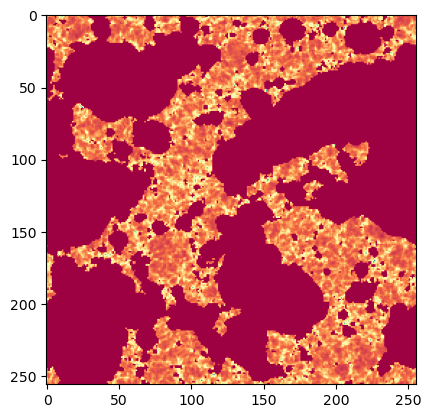

In [ ]:

plt.imshow(cosmo_1, cmap='Spectral')
plt.savefig("Cube Example.png", dpi=600, bbox_inches='tight')


### Local entropy enhancement
Calculate neighbourhood entropy using a disk-shaped footprint. This measures local texture/variation, not ionization directly; intensity rescaling and footprint radius affect the result.


In [ ]:
image = cosmo_1  # Dummy brightness temperature map

# --- 2. Apply Local Entropy ---
entropy_input = img_as_ubyte(exposure.rescale_intensity(image))
entropy_map = entropy(entropy_input, morphology.disk(3))

# --- 3. Apply Unsharp Masking to sharpen edges ---
sharpened = unsharp_mask(entropy_map, radius=20, amount=1)

fig, axes = plt.subplots(1, 3, figsize=(20, 5))

axes[0].imshow(image, cmap='gray')
axes[0].set_title("Original Image")
axes[0].axis('off')

axes[1].imshow(entropy_map, cmap='gray')
axes[1].set_title("Entropy Map")
axes[1].axis('off')

axes[2].imshow(sharpened, cmap='gray')
axes[2].set_title("Unsharp Masked")
axes[2].axis('off')

plt.tight_layout()
plt.show()

NameError: name 'cosmo_1' is not defined

### Local/adaptive thresholding
Compute a spatially varying threshold using a neighbourhood window. Check that `block_size` is odd and appropriate for the image dimensions, and record the offset because it changes the classified area.


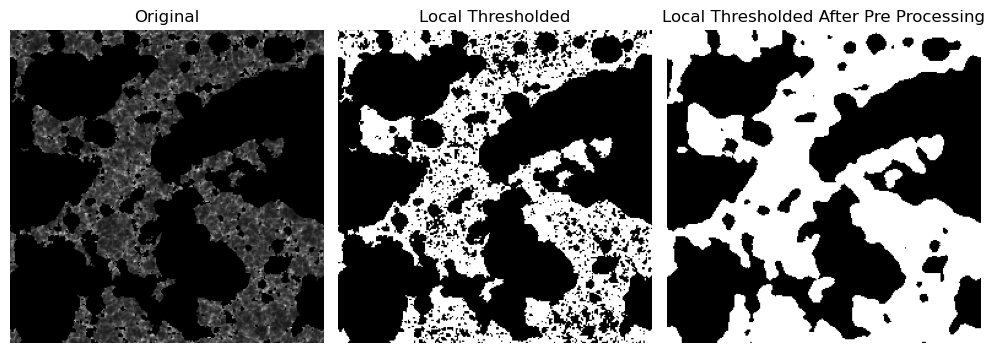

In [ ]:
import numpy as np
import matplotlib.pyplot as plt
from skimage.filters import threshold_local
from skimage import io  # or use your cosmo_1

# Assuming cosmo_1 is your 2D image from a z-slice
# Make sure it's float type for proper thresholding
image = cosmo_1.astype(float)
image2 = sharpened.astype(float)

# Set block size for local thresholding (must be odd)
block_size = 121  # you can experiment with values like 31, 51, 101
offset = 0  # adjust if needed to shift the threshold

# Compute the local threshold map
local_thresh = threshold_local(image, block_size, offset=offset)
local_thresh2 = threshold_local(image2, block_size, offset=offset)

# Apply threshold: pixels > local threshold → foreground (True)
binary_local = image > local_thresh
binary_local2 = image2 > local_thresh2
# Plot original and thresholded image
fig, ax = plt.subplots(1, 3, figsize=(10, 5))
plt.gray()

ax[0].imshow(image)
ax[0].set_title("Original")

ax[1].imshow(binary_local)
ax[1].set_title("Local Thresholded")

ax[2].imshow(binary_local2)
ax[2].set_title("Local Thresholded After Pre Processing")

for a in ax:
    a.axis('off')

plt.tight_layout()
plt.show()


### Unsharp masking
Enhance local edges by adding a scaled high-frequency residual to a smoothed image. Inspect the `radius` and `amount` settings because sharpening can amplify noise and create halos.


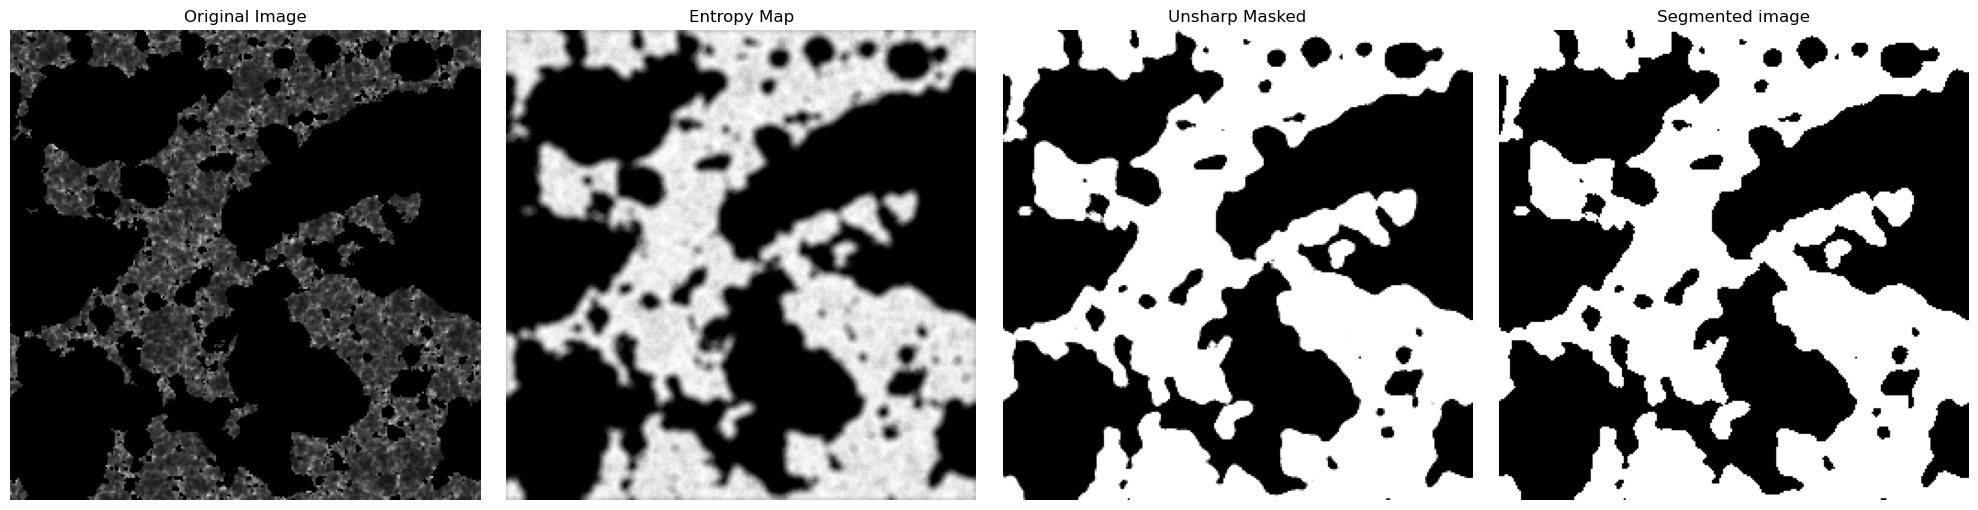

In [ ]:
import matplotlib.pyplot as plt
fig, axes = plt.subplots(1, 4, figsize=(20, 5))

axes[0].imshow(image, cmap='gray')
axes[0].set_title("Original Image")
axes[0].axis('off')

axes[1].imshow(entropy_map, cmap='gray')
axes[1].set_title("Entropy Map")
axes[1].axis('off')

axes[2].imshow(sharpened, cmap='gray')
axes[2].set_title("Unsharp Masked")
axes[2].axis('off')

axes[3].imshow(binary_local2, cmap='gray')
axes[3].set_title("Segmented image")
axes[3].axis('off')

plt.savefig("Pipeline grey p.png", dpi=600, bbox_inches='tight')

plt.tight_layout()
plt.show()

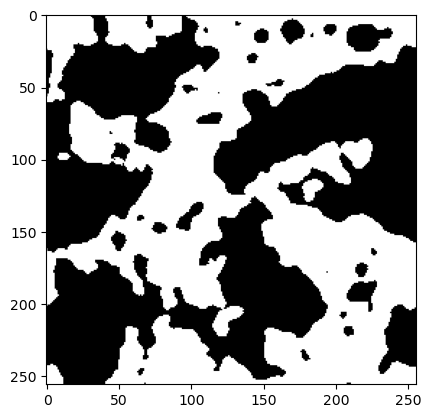

In [ ]:
plt.imshow(binary_local2, cmap='grey')
plt.savefig("Slice_7 LT.png", dpi=600, bbox_inches='tight')


### Histogram diagnostics
Compare pixel-value distributions before and after processing. Histograms describe intensity distributions; by themselves they do not validate physical recovery of H II regions.


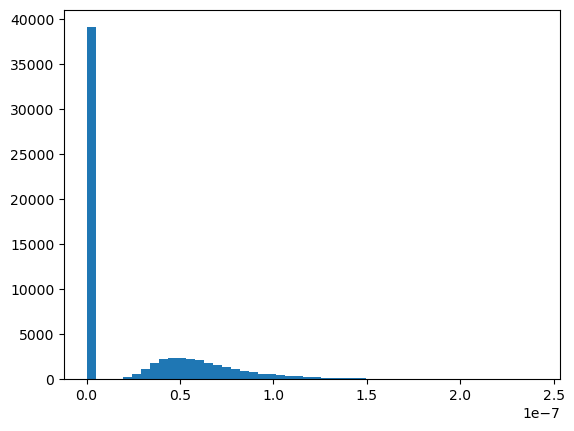

In [ ]:
plt.hist(cosmo_1.flatten().astype(float), bins=50)
plt.show()

### Histogram diagnostics
Compare pixel-value distributions before and after processing. Histograms describe intensity distributions; by themselves they do not validate physical recovery of H II regions.


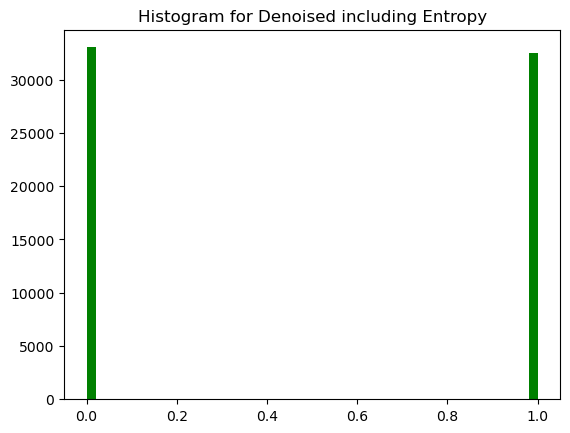

In [ ]:
plt.hist(entropy_map3.astype(float).flatten(), bins=50, color='Green')
plt.title('Histogram for Denoised including Entropy')
plt.show()